In [1]:
import pandas as pd, numpy as np

val = pd.read_parquet("data/fuzzy/val.parquet")
LABELS = [c[2:] for c in val.columns if c.startswith("p_") and c != "p_attack"]
print(val.shape, "|", len(LABELS), "classes")

# how dangerous each attack type is (0 = harmless, 1 = worst). Our design choice.
SEVERITY = {
    "BENIGN": 0.0,
    "PortScan": 0.3,                                      # reconnaissance, no damage yet
    "FTP-Patator": 0.5, "SSH-Patator": 0.5,               # trying to break in
    "Web Attack - Brute Force": 0.5, "Web Attack - XSS": 0.6,
    "DoS Hulk": 0.8, "DoS GoldenEye": 0.8,                # service damage
    "DoS slowloris": 0.8, "DoS Slowhttptest": 0.8, "DDoS": 0.9,
    "Web Attack - Sql Injection": 0.9,                    # data theft
    "Bot": 0.9, "Infiltration": 1.0, "Heartbleed": 1.0,   # machine already compromised / secrets leaked
}

# the "correct" risk level for each true label: 0 = Monitor, 1 = Investigate, 2 = High
TRUE_RISK = {l: 0 if l == "BENIGN" else (1 if SEVERITY[l] < 0.7 else 2) for l in LABELS}

# input 3: severity of the most likely ATTACK type (ignoring benign)
attack_cols = ["p_" + l for l in LABELS if l != "BENIGN"]
top_attack = val[attack_cols].idxmax(axis=1).str[2:]
val["severity"] = top_attack.map(SEVERITY)

val["true_risk"] = val["label"].map(TRUE_RISK)

INPUTS = ["anomaly_pct", "p_attack", "severity", "scan_evidence"]
print(val["true_risk"].value_counts().sort_index())
val.groupby("label")[INPUTS].median().round(2)

(565550, 23) | 15 classes
true_risk
0    454240
1     34958
2     76352
Name: count, dtype: int64


,anomaly_pct,p_attack,severity,scan_evidence
label,,,,
BENIGN,0.50,0.00,1.0,0.25
Bot,0.72,1.00,0.9,0.50
DDoS,0.89,1.00,0.9,0.00
DoS GoldenEye,0.73,1.00,0.8,0.00
DoS Hulk,0.85,1.00,0.8,0.00
DoS Slowhttptest,0.96,1.00,0.8,0.00
DoS slowloris,0.99,1.00,0.8,0.00
FTP-Patator,0.87,1.00,0.5,0.00
Heartbleed,0.98,0.43,1.0,0.89


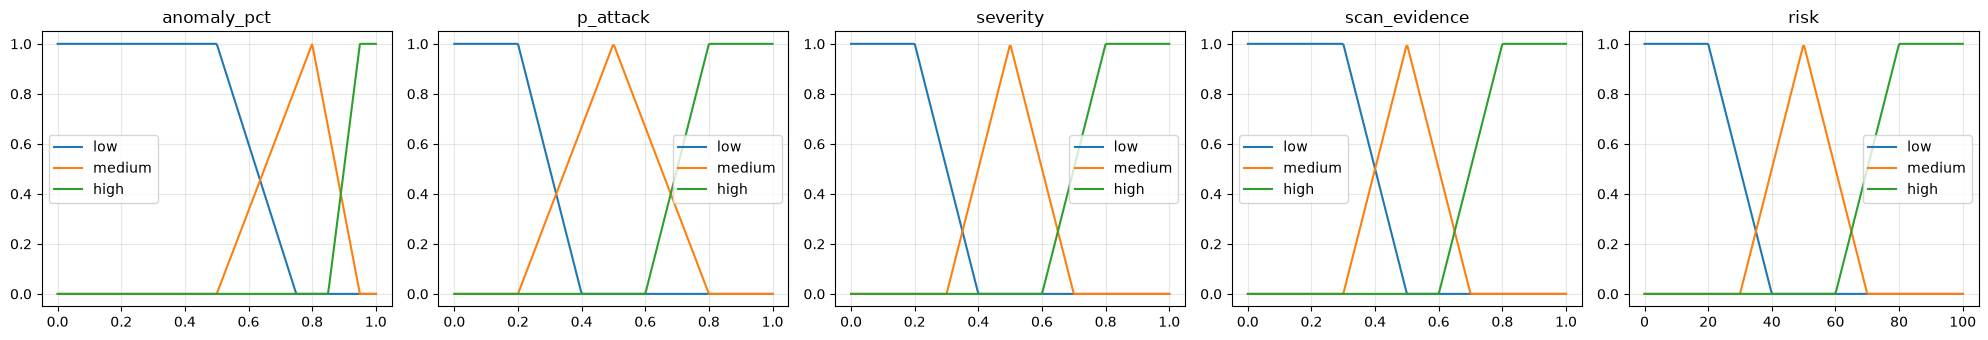

{'low': 0.0, 'medium': 0.47, 'high': 0.3}


In [3]:
import matplotlib.pyplot as plt

def trimf(x, a, b, c):
    """Triangle: 0 at a, rises to 1 at b, falls to 0 at c."""
    return np.clip(np.minimum((x - a) / (b - a + 1e-9), (c - x) / (c - b + 1e-9)), 0, 1)

def trapmf(x, a, b, c, d):
    """Trapezoid: 0 at a, rises to 1 at b, flat until c, falls to 0 at d.
    If a == b (or c == d) the edge is a vertical wall instead of a slope."""
    x = np.asarray(x, dtype=np.float32)
    left = (x - a) / (b - a) if b > a else (x >= a).astype(np.float32)
    right = (d - x) / (d - c) if d > c else (x <= d).astype(np.float32)
    return np.clip(np.minimum(np.minimum(left, right), 1), 0, 1)
# (shape, points) for Low / Medium / High of each input, all on a 0-1 scale
MF = {
    "anomaly_pct":   {"low": ("trap", [0, 0, 0.5, 0.75]),  "medium": ("tri", [0.5, 0.8, 0.95]), "high": ("trap", [0.85, 0.95, 1, 1])},
    "p_attack":      {"low": ("trap", [0, 0, 0.2, 0.4]),   "medium": ("tri", [0.2, 0.5, 0.8]),  "high": ("trap", [0.6, 0.8, 1, 1])},
    "severity":      {"low": ("trap", [0, 0, 0.2, 0.4]),   "medium": ("tri", [0.3, 0.5, 0.7]),  "high": ("trap", [0.6, 0.8, 1, 1])},
    "scan_evidence": {"low": ("trap", [0, 0, 0.3, 0.5]),   "medium": ("tri", [0.3, 0.5, 0.7]),  "high": ("trap", [0.6, 0.8, 1, 1])},
}
# output: risk score 0-100
RISK_MF = {"low": ("trap", [0, 0, 20, 40]), "medium": ("tri", [30, 50, 70]), "high": ("trap", [60, 80, 100, 100])}

def mu(x, shape, pts):
    return trimf(x, *pts) if shape == "tri" else trapmf(x, *pts)

# plot all membership functions
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, (name, sets) in zip(axes, list(MF.items()) + [("risk", RISK_MF)]):
    xs = np.linspace(0, 100 if name == "risk" else 1, 300)
    for s, (shape, pts) in sets.items():
        ax.plot(xs, mu(xs, shape, pts), label=s)
    ax.set_title(name); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
from pathlib import Path; Path("results/fuzzy").mkdir(parents=True, exist_ok=True)
plt.savefig("results/fuzzy/membership_functions.png", dpi=120)
plt.show()

# example: how fuzzy sees one value
x = np.array([0.88])
print({s: round(float(mu(x, *MF["anomaly_pct"][s])[0]), 2) for s in MF["anomaly_pct"]})

In [4]:
# each rule: (IF conditions, THEN risk, explanation). Conditions are joined with AND.
RULES = [
    ([("p_attack", "high"), ("severity", "high"), ("anomaly_pct", "not low")], "high",   "R1 confident severe attack + unusual traffic"),
    ([("p_attack", "high"), ("severity", "high"), ("anomaly_pct", "low")],     "medium", "R2 severe attack type but traffic looks normal"),
    ([("p_attack", "high"), ("severity", "medium")],                           "medium", "R3 confident break-in attempt"),
    ([("p_attack", "high"), ("severity", "low")],                              "medium", "R4 confident reconnaissance"),
    ([("anomaly_pct", "high"), ("severity", "high")],                          "high",   "R5 very unusual + resembles a severe attack"),
    ([("anomaly_pct", "high"), ("p_attack", "low")],                           "medium", "R6 very unusual but unknown: possible new attack"),
    ([("scan_evidence", "high"), ("p_attack", "not low")],                     "medium", "R7 IP hopping across many ports"),
    ([("p_attack", "medium")],                                                 "medium", "R8 classifier unsure"),
    ([("p_attack", "low"), ("anomaly_pct", "not high")],                       "low",    "R9 normal-looking and not flagged"),
]
SETS = ["low", "medium", "high"]
Z = np.linspace(0, 100, 101)                                    # risk axis 0..100
RISK_CURVES = np.stack([mu(Z, *RISK_MF[s]) for s in SETS])      # 3 output shapes

def degree(df, inp, s):
    """How much each row belongs to a fuzzy set (supports 'not low' etc.)."""
    x = df[inp].to_numpy(dtype=np.float32)
    if s.startswith("not "):
        return 1 - mu(x, *MF[inp][s[4:]])
    return mu(x, *MF[inp][s])

def fuzzy_risk(df, chunk=50_000):
    # 1. how strongly each rule fires: AND = min of its conditions
    fire = np.stack([np.minimum.reduce([degree(df, i, s) for i, s in conds])
                     for conds, _, _ in RULES], axis=1)
    # 2. strength of each output set: OR = max over the rules pointing to it
    out = np.zeros((len(df), 3), np.float32)
    for r, (_, target, _) in enumerate(RULES):
        k = SETS.index(target)
        out[:, k] = np.maximum(out[:, k], fire[:, r])
    # 3. cut each output shape at its strength, merge them, take the centre of mass (centroid)
    risk = np.zeros(len(df), np.float32)
    for a in range(0, len(df), chunk):
        agg = np.minimum(out[a:a + chunk, :, None], RISK_CURVES[None]).max(axis=1)
        area = agg.sum(axis=1)
        risk[a:a + chunk] = np.where(area > 0, (agg * Z).sum(axis=1) / np.maximum(area, 1e-9), 0)
    return risk, fire

def to_level(risk):
    return np.select([risk < 35, risk < 65], [0, 1], default=2)   # 0 Monitor, 1 Investigate, 2 High

# run on all val flows
val["risk"], fire = fuzzy_risk(val)
val["level"] = to_level(val["risk"].to_numpy())
val["top_rule"] = np.array([r[2] for r in RULES])[fire.argmax(axis=1)]

from sklearn.metrics import cohen_kappa_score
print("matches true risk:", round((val["level"] == val["true_risk"]).mean(), 4))
print("weighted kappa:   ", round(cohen_kappa_score(val["true_risk"], val["level"], weights="quadratic"), 4))
print("BENIGN flows sent to High:", int(((val["label"] == "BENIGN") & (val["level"] == 2)).sum()))
pd.crosstab(val["label"], val["level"].map({0: "Monitor", 1: "Investigate", 2: "High"}))

matches true risk: 0.8656
weighted kappa:    0.7285
BENIGN flows sent to High: 29401


level,High,Investigate,Monitor
label,,,
BENIGN,29401,29848,394991
Bot,161,173,57
DDoS,20924,4681,0
DoS GoldenEye,1420,639,0
DoS Hulk,34890,11134,1
DoS Slowhttptest,1053,32,15
DoS slowloris,1145,9,5
FTP-Patator,0,1587,0
Heartbleed,2,0,0


In [5]:
benign = val[val["label"] == "BENIGN"]
print("benign -> High, top rule:")
print(benign.loc[benign["level"] == 2, "top_rule"].value_counts())
print("\nbenign -> Investigate, top rule:")
print(benign.loc[benign["level"] == 1, "top_rule"].value_counts())
print("\nbenign flows the classifier itself flags (p_attack > 0.5):", int((benign["p_attack"] > 0.5).sum()))

benign -> High, top rule:
top_rule
R5 very unusual + resembles a severe attack         28696
R6 very unusual but unknown: possible new attack      553
R1 confident severe attack + unusual traffic          100
R7 IP hopping across many ports                        32
R8 classifier unsure                                   14
R2 severe attack type but traffic looks normal          6
Name: count, dtype: int64

benign -> Investigate, top rule:
top_rule
R5 very unusual + resembles a severe attack         16076
R9 normal-looking and not flagged                   12520
R2 severe attack type but traffic looks normal        495
R7 IP hopping across many ports                       472
R8 classifier unsure                                  199
R6 very unusual but unknown: possible new attack       59
R3 confident break-in attempt                          27
Name: count, dtype: int64

benign flows the classifier itself flags (p_attack > 0.5): 1011


In [6]:
# 1. a stricter anomaly level, for "possible new attack"
MF["anomaly_pct"]["extreme"] = ("trap", [0.95, 0.99, 1, 1])

# 2. updated rules (R5, R6, R9 changed)
RULES = [
    ([("p_attack", "high"), ("severity", "high"), ("anomaly_pct", "not low")],    "high",   "R1 confident severe attack + unusual traffic"),
    ([("p_attack", "high"), ("severity", "high"), ("anomaly_pct", "low")],        "medium", "R2 severe attack type but traffic looks normal"),
    ([("p_attack", "high"), ("severity", "medium")],                              "medium", "R3 confident break-in attempt"),
    ([("p_attack", "high"), ("severity", "low")],                                 "medium", "R4 confident reconnaissance"),
    ([("anomaly_pct", "high"), ("severity", "high"), ("p_attack", "not low")],    "high",   "R5 very unusual + resembles a severe attack + some suspicion"),
    ([("anomaly_pct", "extreme"), ("p_attack", "low")],                           "medium", "R6 extremely unusual but unknown: possible new attack"),
    ([("scan_evidence", "high"), ("p_attack", "not low")],                        "medium", "R7 IP hopping across many ports"),
    ([("p_attack", "medium")],                                                    "medium", "R8 classifier unsure"),
    ([("p_attack", "low"), ("anomaly_pct", "not extreme")],                       "low",    "R9 normal-looking and not flagged"),
]

# 3. rerun and compare
val["risk"], fire = fuzzy_risk(val)
val["level"] = to_level(val["risk"].to_numpy())
val["top_rule"] = np.array([r[2] for r in RULES])[fire.argmax(axis=1)]

print("matches true risk:", round((val["level"] == val["true_risk"]).mean(), 4))
print("weighted kappa:   ", round(cohen_kappa_score(val["true_risk"], val["level"], weights="quadratic"), 4))
print("BENIGN flows sent to High:       ", int(((val["label"] == "BENIGN") & (val["level"] == 2)).sum()))
print("BENIGN flows sent to Investigate:", int(((val["label"] == "BENIGN") & (val["level"] == 1)).sum()))
pd.crosstab(val["label"], val["level"].map({0: "Monitor", 1: "Investigate", 2: "High"}))

matches true risk: 0.9469
weighted kappa:    0.9406
BENIGN flows sent to High:        177
BENIGN flows sent to Investigate: 13057


level,High,Investigate,Monitor
label,,,
BENIGN,177,13057,441006
Bot,138,156,97
DDoS,20924,4681,0
DoS GoldenEye,1420,639,0
DoS Hulk,34890,11134,1
DoS Slowhttptest,1043,9,48
DoS slowloris,1145,9,5
FTP-Patator,0,1587,0
Heartbleed,2,0,0


In [7]:
def crisp_levels(df, use_anomaly):
    """Traditional hard thresholds, no fuzzy."""
    lvl = np.zeros(len(df), int)
    attack = df["p_attack"].to_numpy() > 0.5
    sev = df["severity"].to_numpy()
    lvl[attack & (sev < 0.7)] = 1          # attack, medium danger -> Investigate
    lvl[attack & (sev >= 0.7)] = 2         # attack, high danger -> High
    if use_anomaly:
        weird = ~attack & (df["anomaly_pct"].to_numpy() > 0.99)
        lvl[weird] = 1                     # not flagged but very weird -> Investigate
    return lvl

def summary(name, lvl):
    t = val["true_risk"].to_numpy()
    b = (val["label"] == "BENIGN").to_numpy()
    return {
        "method": name,
        "match": round((lvl == t).mean(), 4),
        "kappa": round(cohen_kappa_score(t, lvl, weights="quadratic"), 4),
        "benign->High": int((b & (lvl == 2)).sum()),
        "benign->Investigate": int((b & (lvl == 1)).sum()),
        "attacks missed (Monitor)": int((~b & (lvl == 0)).sum()),
        "severe not High": int(((t == 2) & (lvl < 2)).sum()),
    }

val["crisp_A"] = crisp_levels(val, use_anomaly=False)
val["crisp_B"] = crisp_levels(val, use_anomaly=True)

compare = pd.DataFrame([
    summary("crisp A: classifier only", val["crisp_A"].to_numpy()),
    summary("crisp B: classifier + anomaly", val["crisp_B"].to_numpy()),
    summary("fuzzy: hand-made rules", val["level"].to_numpy()),
]).set_index("method")
print(compare.to_string())

# the hard cases: how each method treats the rare / unknown-ish attacks
names = {0: "Monitor", 1: "Investigate", 2: "High"}
for lab in ["Heartbleed", "Infiltration", "Web Attack - Sql Injection", "Bot"]:
    rows = val[val["label"] == lab]
    print(f"\n{lab} ({len(rows)} flows)")
    for m in ["crisp_A", "crisp_B", "level"]:
        print(f"  {m:8s}", rows[m].map(names).value_counts().to_dict())

                                match   kappa  benign->High  benign->Investigate  attacks missed (Monitor)  severe not High
method                                                                                                                     
crisp A: classifier only       0.9979  0.9917           972                   39                       174              180
crisp B: classifier + anomaly  0.9899  0.9837           972                 4582                       167              180
fuzzy: hand-made rules         0.9469  0.9406           177                13057                       152            16782

Heartbleed (2 flows)
  crisp_A  {'Monitor': 2}
  crisp_B  {'Monitor': 2}
  level    {'High': 2}

Infiltration (7 flows)
  crisp_A  {'High': 6, 'Monitor': 1}
  crisp_B  {'High': 6, 'Investigate': 1}
  level    {'High': 6, 'Investigate': 1}

Web Attack - Sql Injection (4 flows)
  crisp_A  {'High': 3, 'Investigate': 1}
  crisp_B  {'High': 3, 'Investigate': 1}
  level    {'Investi

In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F
torch.manual_seed(42)

def to_trap(shape, pts):
    """Write every set as a trapezoid (a, b, c, d). A triangle is a trapezoid with a tiny flat top.
    Vertical walls at 0 / 1 become short slopes just outside 0-1, so they can be learned too."""
    a, b, c, d = (pts[0], pts[1], pts[1] + 1e-3, pts[2]) if shape == "tri" else pts
    if b - a < 1e-3: a = b - 0.05
    if d - c < 1e-3: d = c + 0.05
    return [a, b, c, d]

def inv_softplus(w):
    return float(np.log(np.expm1(max(w, 1e-4))))

class NeuroFuzzy(nn.Module):
    def __init__(self):
        super().__init__()
        self.keys = [(inp, s) for inp in MF for s in MF[inp]]          # every fuzzy set
        start, widths = [], []
        for inp, s in self.keys:
            a, b, c, d = to_trap(*MF[inp][s])
            start.append(a)
            widths.append([inv_softplus(b - a), inv_softplus(c - b), inv_softplus(d - c)])
        self.start = nn.Parameter(torch.tensor(start))               # learnable: left corner of each set
        self.widths = nn.Parameter(torch.tensor(widths))             # learnable: gaps between corners (kept > 0)
        self.centres_raw = nn.Parameter(torch.tensor([15.0, inv_softplus(35.0), inv_softplus(32.0)]))  # risk of low/medium/high
        self.cuts_raw = nn.Parameter(torch.tensor([35.0, inv_softplus(30.0)]))                         # Monitor | Investigate | High

    def corners(self):
        w = F.softplus(self.widths) + 1e-3
        a = self.start; b = a + w[:, 0]; c = b + w[:, 1]; d = c + w[:, 2]
        return a, b, c, d

    def centres(self):
        lo = self.centres_raw[0]
        me = lo + F.softplus(self.centres_raw[1])
        return torch.stack([lo, me, me + F.softplus(self.centres_raw[2])])

    def cuts(self):
        t1 = self.cuts_raw[0]
        return t1, t1 + F.softplus(self.cuts_raw[1])

    def forward(self, x):                                             # x: [N, 4] in INPUTS order
        a, b, c, d = self.corners()
        mu_ = {}
        for k, (inp, s) in enumerate(self.keys):
            xi = x[:, INPUTS.index(inp)]
            mu_[(inp, s)] = torch.clamp(torch.minimum((xi - a[k]) / (b[k] - a[k]), (d[k] - xi) / (d[k] - c[k])), 0, 1)
        fire = []
        for conds, target, _ in RULES:
            degs = [1 - mu_[(i, s[4:])] if s.startswith("not ") else mu_[(i, s)] for i, s in conds]
            fire.append(torch.stack(degs).min(dim=0).values)          # AND = min
        fire = torch.stack(fire, 1)
        out = torch.stack([fire[:, [r for r, R in enumerate(RULES) if R[1] == s]].max(1).values
                           for s in SETS], 1)                         # OR = max, per output level
        risk = (out * self.centres()).sum(1) / out.sum(1).clamp_min(1e-6)   # weighted average of the 3 centres
        return risk, fire

def soft_levels(risk, t1, t2, temp=3.0):
    """Smooth version of the cut-offs (so gradients can flow): probability of Monitor / Investigate / High."""
    p1 = torch.sigmoid((risk - t1) / temp)
    p2 = torch.sigmoid((risk - t2) / temp)
    return torch.stack([1 - p1, p1 - p2, p2], 1)

# cost of each mistake. rows = true level, cols = given level (Monitor, Investigate, High)
COST = torch.tensor([[0.0,  1.0, 5.0],    # benign:        Investigate = mild, High = bad
                     [10.0, 0.0, 1.0],    # medium attack: missed = very bad
                     [20.0, 3.0, 0.0]])   # severe attack: missed = worst, only Investigate = medium

X = torch.tensor(val[INPUTS].to_numpy(np.float32))
T = torch.tensor(val["true_risk"].to_numpy(np.int64))

model = NeuroFuzzy()
opt = torch.optim.Adam(model.parameters(), lr=0.01)
for step in range(301):
    risk, _ = model(X)
    t1, t2 = model.cuts()
    loss = (soft_levels(risk, t1, t2) * COST[T]).sum(1).mean()       # average cost per flow
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 50 == 0:
        print(f"step {step:3d}  cost {loss.item():.4f}  cuts {t1.item():.1f} / {t2.item():.1f}")

# final hard levels with the tuned system
with torch.no_grad():
    risk, fire_t = model(X)
    t1, t2 = model.cuts()
val["risk_tuned"] = risk.numpy()
val["level_tuned"] = np.select([val["risk_tuned"] < t1.item(), val["risk_tuned"] < t2.item()], [0, 1], default=2)

compare.loc["fuzzy: tuned (neuro-fuzzy)"] = pd.Series(summary("x", val["level_tuned"].to_numpy())).drop("method")
print(compare.to_string())

for lab in ["Heartbleed", "Infiltration", "Web Attack - Sql Injection", "Bot"]:
    rows = val[val["label"] == lab]
    print(f"{lab:28s}", rows["level_tuned"].map(names).value_counts().to_dict())

torch.save(model.state_dict(), "models/neuro_fuzzy.pt")

step   0  cost 0.1300  cuts 35.0 / 65.0
step  50  cost 1.7899  cuts 34.6 / 64.3
step 100  cost 1.7888  cuts 34.5 / 64.3
step 150  cost 1.7886  cuts 34.4 / 64.4
step 200  cost 1.7882  cuts 34.4 / 64.6
step 250  cost 1.7803  cuts 34.4 / 64.8
step 300  cost 0.0269  cuts 33.8 / 63.6
                                match   kappa  benign->High  benign->Investigate  attacks missed (Monitor)  severe not High
method                                                                                                                     
crisp A: classifier only       0.9979  0.9917           972                   39                       174              180
crisp B: classifier + anomaly  0.9899  0.9837           972                 4582                       167              180
fuzzy: hand-made rules         0.9469  0.9406           177                13057                       152            16782
fuzzy: tuned (neuro-fuzzy)     0.9981  0.9938           599                  165                    

In [9]:
# class weights: every true label matters, however rare (softened with sqrt, like the classifier)
counts = val["label"].value_counts()
w = np.sqrt(len(val) / (len(counts) * counts))
W = torch.tensor(val["label"].map(w).to_numpy(np.float32))
W = W / W.mean()

model = NeuroFuzzy()
opt = torch.optim.Adam(model.parameters(), lr=0.002)      # smaller steps = stable
best_cost, best_state = float("inf"), None
for step in range(801):
    risk, _ = model(X)
    t1, t2 = model.cuts()
    per_flow = (soft_levels(risk, t1, t2) * COST[T]).sum(1)
    loss = (per_flow * W).mean()                          # weighted: rare attacks count more
    opt.zero_grad(); loss.backward(); opt.step()
    if loss.item() < best_cost:                           # remember the best version
        best_cost = loss.item()
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    if step % 100 == 0:
        print(f"step {step:3d}  cost {loss.item():.4f}  cuts {t1.item():.1f} / {t2.item():.1f}")
model.load_state_dict(best_state)
print("best cost:", round(best_cost, 4))

step   0  cost 0.3508  cuts 35.0 / 65.0
step 100  cost 0.2556  cuts 34.8 / 64.6
step 200  cost 0.1251  cuts 34.6 / 64.3
step 300  cost 0.1449  cuts 34.6 / 64.2
step 400  cost 0.1553  cuts 34.5 / 64.1
step 500  cost 0.1522  cuts 34.4 / 64.1
step 600  cost 0.1551  cuts 34.3 / 64.1
step 700  cost 0.1494  cuts 34.2 / 64.0
step 800  cost 0.1481  cuts 34.1 / 64.0
best cost: 0.1244


In [10]:
compare = compare.drop("fuzzy: tuned (neuro-fuzzy)", errors="ignore")

with torch.no_grad():
    risk, fire_t = model(X)
    t1, t2 = model.cuts()
val["risk_tuned"] = risk.numpy()
val["level_tuned"] = np.select([val["risk_tuned"] < t1.item(), val["risk_tuned"] < t2.item()], [0, 1], default=2)

compare.loc["fuzzy: tuned (neuro-fuzzy)"] = pd.Series(summary("x", val["level_tuned"].to_numpy())).drop("method")
print(compare.to_string())

for lab in ["Heartbleed", "Infiltration", "Web Attack - Sql Injection", "Bot"]:
    rows = val[val["label"] == lab]
    print(f"{lab:28s}", rows["level_tuned"].map(names).value_counts().to_dict())

torch.save(model.state_dict(), "models/neuro_fuzzy.pt")
print("cuts:", round(t1.item(), 1), "/", round(t2.item(), 1))

                                match   kappa  benign->High  benign->Investigate  attacks missed (Monitor)  severe not High
method                                                                                                                     
crisp A: classifier only       0.9979  0.9917           972                   39                       174              180
crisp B: classifier + anomaly  0.9899  0.9837           972                 4582                       167              180
fuzzy: hand-made rules         0.9469  0.9406           177                13057                       152            16782
fuzzy: tuned (neuro-fuzzy)     0.9914  0.9882           415                 4228                       184              192
Heartbleed                   {'High': 2}
Infiltration                 {'High': 6, 'Investigate': 1}
Web Attack - Sql Injection   {'High': 3, 'Investigate': 1}
Bot                          {'High': 281, 'Monitor': 105, 'Investigate': 5}
cuts: 34.7 / 64.3


In [11]:
test = pd.read_parquet("data/fuzzy/test.parquet")
test["severity"] = test[attack_cols].idxmax(axis=1).str[2:].map(SEVERITY)
test["true_risk"] = test["label"].map(TRUE_RISK)

# 1. all four methods, exactly as built on val
test["crisp_A"] = crisp_levels(test, use_anomaly=False)
test["crisp_B"] = crisp_levels(test, use_anomaly=True)
r_hand, _ = fuzzy_risk(test)
test["fuzzy_hand"] = to_level(r_hand)
with torch.no_grad():
    r_t, fire_t = model(torch.tensor(test[INPUTS].to_numpy(np.float32)))
    c1, c2 = model.cuts()
test["risk"] = r_t.numpy()
test["fuzzy_tuned"] = np.select([test["risk"] < c1.item(), test["risk"] < c2.item()], [0, 1], default=2)
test["top_rule"] = np.array([R[2] for R in RULES])[fire_t.numpy().argmax(1)]

# 2. the same scores as on val
def score(df, name, lvl):
    t = df["true_risk"].to_numpy(); b = (df["label"] == "BENIGN").to_numpy()
    return {"method": name,
            "match": round((lvl == t).mean(), 4),
            "kappa": round(cohen_kappa_score(t, lvl, weights="quadratic"), 4),
            "benign->High": int((b & (lvl == 2)).sum()),
            "benign->Investigate": int((b & (lvl == 1)).sum()),
            "attacks missed (Monitor)": int((~b & (lvl == 0)).sum()),
            "severe not High": int(((t == 2) & (lvl < 2)).sum())}

final = pd.DataFrame([score(test, n, test[c].to_numpy()) for n, c in [
    ("crisp A: classifier only", "crisp_A"), ("crisp B: classifier + anomaly", "crisp_B"),
    ("fuzzy: hand-made rules", "fuzzy_hand"), ("fuzzy: tuned (neuro-fuzzy)", "fuzzy_tuned")]]).set_index("method")
print(final.to_string())
final.to_csv("results/fuzzy/final_test_comparison.csv")

# 3. the hard cases
for lab in ["Heartbleed", "Infiltration", "Web Attack - Sql Injection", "Bot"]:
    rows = test[test["label"] == lab]
    print(f"\n{lab} ({len(rows)} flows)")
    for m in ["crisp_A", "fuzzy_tuned"]:
        print(f"  {m:12s}", rows[m].map(names).value_counts().to_dict())

# 4. save everything for the dashboard
test.to_parquet("data/fuzzy/test_scored.parquet", index=False)
print("\nsaved")

                                match   kappa  benign->High  benign->Investigate  attacks missed (Monitor)  severe not High
method                                                                                                                     
crisp A: classifier only       0.9944  0.9779           976                   72                      2048             2097
crisp B: classifier + anomaly  0.9850  0.9685           976                 5359                      2045             2097
fuzzy: hand-made rules         0.9247  0.9050           126                14487                      1392            27940
fuzzy: tuned (neuro-fuzzy)     0.9852  0.9700           379                 4806                      2342             3156

Heartbleed (2 flows)
  crisp_A      {'High': 2}
  fuzzy_tuned  {'High': 2}

Infiltration (7 flows)
  crisp_A      {'Monitor': 4, 'High': 3}
  fuzzy_tuned  {'High': 3, 'Investigate': 2, 'Monitor': 2}

Web Attack - Sql Injection (4 flows)
  crisp_A      {'H

In [12]:
# bring back IP, ports and time for each test flow (same sort as in preprocessing, so row numbers match)
meta = pd.read_parquet("data/processed/full_ready.parquet",
                       columns=["split", "Source IP", "ts", "Destination IP", "Destination Port"])
meta = meta.sort_values(["split", "Source IP", "ts"], kind="stable").reset_index(drop=True)

info = meta.iloc[test["row"].to_numpy()].reset_index(drop=True)
print("all rows are test rows:", (info["split"] == "test").all())   # sanity check, must be True

dash = pd.concat([test.reset_index(drop=True), info.drop(columns="split")], axis=1)
keep = ["ts", "Source IP", "Destination IP", "Destination Port", "label", "pred", "p_attack",
        "anomaly_pct", "severity", "scan_evidence", "risk", "fuzzy_tuned", "crisp_A", "top_rule"]
dash[keep].to_parquet("data/fuzzy/dashboard.parquet", index=False)
print("saved", dash.shape)

all rows are test rows: True
saved (565545, 35)
